# Mineração de Dados

Dataset UCMF_raw.csv com 12.873 consultas de cardiologia pediátrica do Real Hospital Português (Recife), 21 colunas.
Variável-alvo: NORMAL X ANORMAL

Etapas:

0. Leitura (arquivo inalterado)
1. Padronização das variáveis categóricas
2. Conversão da FC para numérico
3. Definir limites 
4. Recuperação e validação da IDADE
5. IMC recalculado
6. Recálculo da PPA
7. HDA e MOTIVO como colunas binárias
8. Análise da ausência de PA
9. Deduplicação
10. Remoções finais de linhas

Nenhuma imputação por média ou mediana é feita aqui, ficando para depois da divisão treino/teste para evitar vazamento de dados.

### Import das libs, guardando versão inalterada para comparações pós limpeza, definindo log para documentação:

In [1]:
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

from pathlib import Path

# Raiz do projeto: a pasta que contém UCMF_raw.csv. Procurar a partir da pasta atual
# para cima faz o notebook funcionar rodando da própria subpasta ou da raiz.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'UCMF_raw.csv').exists())

df = pd.read_csv(RAIZ / 'UCMF_raw.csv')

# Tabelas de crescimento do CDC (etapas 4.1 e 6): lidas de Docs/cdc; se faltarem, são baixadas
# do site oficial ou, se ele falhar, de um espelho, e guardadas lá para as próximas execuções.
CDC_DIR = RAIZ / 'Docs' / 'cdc'
FONTES_CDC = ['https://www.cdc.gov/growthcharts/data/zscore/',
              'https://restoredcdc.org/www.cdc.gov/growthcharts/data/zscore/']


def ler_csv_cdc(nome):
    local = CDC_DIR / nome
    if not local.exists():
        import urllib.request
        CDC_DIR.mkdir(parents=True, exist_ok=True)
        erros = []
        for base in FONTES_CDC:
            try:
                req = urllib.request.Request(base + nome, headers={'User-Agent': 'Mozilla/5.0'})
                with urllib.request.urlopen(req, timeout=60) as r:
                    local.write_bytes(r.read())
                print(f'[cdc] {nome} baixado de {base}')
                break
            except Exception as e:
                erros.append(f'{base}{nome}: {e}')
        else:
            raise RuntimeError('Não foi possível obter a tabela do CDC; coloque os arquivos em Docs/cdc.\n'
                               + '\n'.join(erros))
    return pd.read_csv(local)

# df_raw guarda o dado original intocado
df_raw = df.copy()
# log registra o estado da base depois de cada etapa
log_limpeza = []


def registrar(etapa, dados, descricao):
    #adiciona no log o numero de linhas e de nulos por coluna após cada etapa
    log_limpeza.append({
        'etapa': etapa,
        'linhas': len(dados),
        'nulos': dados.isnull().sum().to_dict(),
        'descricao': descricao,
    })
    print(f'[log] {etapa}: {len(dados)} linhas, {int(dados.isnull().sum().sum())} nulos no total')


registrar('0. Leitura', df, 'CSV sem nenhuma alteração.')

[log] 0. Leitura: 12873 linhas, 56561 nulos no total


## Etapa 0

In [2]:
display(df_raw.head())

,ID,Peso,Altura,IMC,Atendimento,DN,IDADE,Convenio,PULSOS,PA SISTOLICA,PA DIASTOLICA,PPA,NORMAL X ANORMAL,B2,SOPRO,FC,HDA 1,HDA2,SEXO,MOTIVO1,MOTIVO2
0,1,5.0,51,19.0,11/05/06,30/03/06,0.12,GS,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Sistólico,112,Palpitacao,NaN,M,6 - Suspeita de cardiopatia,6 - Palpitação/taquicardia/arritmia
1,2,3.5,50,14.0,25/05/05,19/05/05,0.02,GS,Normais,NaN,NaN,Não Calculado,Anormal,Normal,ausente,128,Dispneia,NaN,M,6 - Suspeita de cardiopatia,6 - Dispnéia
2,3,0.0,0,NaN,12/06/01,08/05/05,-4.05,SULA,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Sistólico,88,Assintomático,NaN,M,2 - Check-up,NaN
3,4,8.1,65,19.0,15/10/09,21/04/09,0.50,NaN,Normais,NaN,NaN,Não Calculado,Anormal,Normal,ausente,92,Assintomático,NaN,M,5 - Parecer cardiológico,NaN
4,7,40.0,151,18.0,14/01/08,14/08/95,12.89,SAME,Normais,NaN,NaN,Não Calculado,Anormal,Normal,ausente,96,Dor precordial,NaN,M,5 - Parecer cardiológico,NaN


In [3]:
display(df_raw.describe())

,ID,Peso,Altura,IMC,IDADE,PA SISTOLICA,PA DIASTOLICA
count,12873.000000,12555.000000,12873.000000,8146.000000,11377.000000,5143.000000,5133.000000
mean,9196.412103,16.614417,66.111474,17.455315,4.856947,101.798561,62.646990
std,5230.972692,16.979814,56.027934,15.008016,8.829742,18.901140,9.092261
min,1.000000,-40.000000,0.000000,0.000000,-113.180000,60.000000,6.000000
25%,4694.000000,3.400000,0.000000,15.000000,0.930000,90.000000,60.000000
50%,9222.000000,12.800000,69.000000,17.000000,3.960000,100.000000,60.000000
75%,13768.000000,24.000000,112.000000,19.000000,8.590000,110.000000,70.000000
max,17873.000000,157.000000,198.000000,848.000000,71.810000,990.000000,120.000000


Tem muitos valores impossíveis como peso negativo, altura 0, IMC absurdo, idade negativa e acima de 19 anos, que excede o limite para análise pediátrica

In [4]:
# Nulos do CSV
print(df_raw.isnull().sum())

ID                      0
Peso                  318
Altura                  0
IMC                  4727
Atendimento           983
DN                   1376
IDADE                1496
Convenio             4108
PULSOS               1194
PA SISTOLICA         7730
PA DIASTOLICA        7740
PPA                   217
NORMAL X ANORMAL     1168
B2                   1178
SOPRO                1167
FC                   1868
HDA 1                4270
HDA2                12466
SEXO                    4
MOTIVO1              1055
MOTIVO2              3496
dtype: int64


Apesar dos dados, várias colunas usam códigos no lugar de vazio, como 0 em peso/altura, 'Não Calculado' na PPA, 'Indeterminado' no SEXO, o que é motivação para a próxima etapa

## Etapa 1 – Padronização das variáveis categóricas

In [5]:
COLS_CATEGORICAS = ['NORMAL X ANORMAL', 'SEXO', 'SOPRO', 'PULSOS', 'B2', 'PPA',
                    'HDA 1', 'HDA2', 'MOTIVO1', 'MOTIVO2']
# obs.: FC é texto no CSV, mas é uma medida numérica que vai ser tratada na etapa 2

# contagens de antes para comparar com o resultado da padronização
print('=== ANTES da padronização ===')
for col in COLS_CATEGORICAS:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False).to_string())

=== ANTES da padronização ===

--- NORMAL X ANORMAL ---
NORMAL X ANORMAL
Normal     6744
Anormal    4959
NaN        1168
anormal       1
Normais       1

--- SEXO ---
SEXO
M                6065
F                4477
Indeterminado    1417
Masculino         584
Feminino          247
masculino          79
NaN                 4

--- SOPRO ---
SOPRO
ausente                   7275
Sistólico                 3648
NaN                       1167
sistólico                  723
contínuo                    28
Contínuo                    20
diastólico                   9
Sistolico e diastólico       3

--- PULSOS ---
PULSOS
Normais                11531
NaN                     1194
Amplos                    52
Femorais diminuidos       39
Outro                     36
Diminuídos                18
NORMAIS                    2
AMPLOS                     1

--- B2 ---
B2
Normal           11098
NaN               1178
Hiperfonética      295
Desdob fixo        149
Única               77
Outro               

In [6]:
# aqui cada dicionário lista todas as variantes encontradas nos dados e 
# como deve ser o valor padronizado
MAPA_HDA = {
    'assintomático': 'Assintomático',
    'dispneia': 'Dispneia',
    'dor precordial': 'Dor precordial',
    'palpitacao': 'Palpitação',
    'cianose': 'Cianose',
    'desmaio/tontura': 'Desmaio/tontura',
    'ganho de peso': 'Ganho de peso',
    'outro': 'Outro',
}

MAPAS = {
    'NORMAL X ANORMAL': {
        'normal': 'Normal',
        'normais': 'Normal',     
        'anormal': 'Anormal',
    },
    'SEXO': {
        'm': 'M', 'masculino': 'M',
        'f': 'F', 'feminino': 'F',
        # 'Indeterminado' não é uma categoria clínica: é o que a planilha grava quando o
        # campo fica vazio. Das 1.417 ocorrências, 871 são registros-esqueleto (linhas quase
        # vazias; aba v8 do levantamento de qualidade), que saem na etapa 4 por não terem
        # IDADE. As demais viram sexo ausente.
        # manter ele criaria um outro grupo - atrapalharia
        'indeterminado': np.nan,
    },
    'SOPRO': {
        'ausente': 'Ausente',
        'sistólico': 'Sistólico', 'sistolico': 'Sistólico',
        'diastólico': 'Diastólico', 'diastolico': 'Diastólico',
        'contínuo': 'Contínuo', 'continuo': 'Contínuo',
        'sistolico e diastólico': 'Sistólico e diastólico',
        'sistólico e diastólico': 'Sistólico e diastólico',
    },
    'PULSOS': {
        'normais': 'Normais',
        'amplos': 'Amplos',
        'diminuídos': 'Diminuídos', 'diminuidos': 'Diminuídos',
        'femorais diminuidos': 'Femorais diminuídos',
        'femorais diminuídos': 'Femorais diminuídos',
        'outro': 'Outro',
    },
    'B2': {
        'normal': 'Normal',
        'hiperfonética': 'Hiperfonética',
        'desdob fixo': 'Desdobramento fixo',
        'única': 'Única',
        'outro': 'Outro',
    },
    'PPA': {
        # 'Não Calculado' e '#VALUE!' indicam ausentes
        'não calculado': np.nan,
        '#value!': np.nan,
        'normal': 'Normal',
        'pre-hipertensão pas': 'Pré-hipertensão PAS',
        'pre-hipertensão pad': 'Pré-hipertensão PAD',
        'has-1 pas': 'HAS-1 PAS',
        'has-1 pad': 'HAS-1 PAD',
        'has-2 pas': 'HAS-2 PAS',
        'has-2 pad': 'HAS-2 PAD',
    },
    'HDA 1': MAPA_HDA,
    'HDA2': MAPA_HDA,
    'MOTIVO1': {
        '1 - cardiopatia já estabelecida': '1 - Cardiopatia já estabelecida',
        '2 - check-up': '2 - Check-up',
        '5 - parecer cardiológico': '5 - Parecer cardiológico',
        '6 - suspeita de cardiopatia': '6 - Suspeita de cardiopatia',
        '7 - outro': '7 - Outro',
    },
    'MOTIVO2': {
        '1 - cardiopatia congenica': '1 - Cardiopatia congênita',
        '1 - cardiopatia adquirida': '1 - Cardiopatia adquirida',
        '5 - cirurgia': '5 - Cirurgia',
        '5 - atividade física': '5 - Atividade física',
        '5 - uso de cisaprida': '5 - Uso de cisaprida',
        '6 - sopro': '6 - Sopro',
        '6 - palpitação/taquicardia/arritmia': '6 - Palpitação/taquicardia/arritmia',
        '6 - dor precordial': '6 - Dor precordial',
        '6 - has/dislipidemia/obesidade': '6 - HAS/dislipidemia/obesidade',
        '6 - dispnéia': '6 - Dispneia',
        '6 - cianose': '6 - Cianose',
        '6 - cianose e dispnéia': '6 - Cianose e dispneia',
        '6 - cardiopatia na familia': '6 - Cardiopatia na família',
        '6 - cansaço': '6 - Cansaço',
        '6 - alterações de pulso/perfusão': '6 - Alterações de pulso/perfusão',
        'outro': 'Outro',
    },
}

In [7]:
def padronizar(serie, mapa):
    #aplica strip + minúsculas e traduz pelo dicionário
    #se aparecer um valor fora do dicionário, o código para com erro em vez de
    #transformar em NaN
    chave = serie.str.strip().str.lower()
    sem_mapa = set(chave.dropna().unique()) - set(mapa)
    if sem_mapa:
        raise ValueError(f'{serie.name}: valores sem mapeamento: {sem_mapa}')
    return chave.map(mapa)


# strip() em todas as colunas de texto
#texto vazio depois do strip é ausência, então vira NaN.
cols_texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for col in cols_texto:
    df[col] = df[col].str.strip().replace('', np.nan)

nulos_antes = df[COLS_CATEGORICAS].isnull().sum()
for col, mapa in MAPAS.items():
    df[col] = padronizar(df[col], mapa)

# !! convenio é removida !! motivos: ~32% de ausentes,
# um monte de grafias para o mesmo plano e nenhuma relação clínica
# com o resultado do exame 
df = df.drop(columns=['Convenio'])

print('=== DEPOIS da padronização ===')
for col in COLS_CATEGORICAS:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False).to_string())

novos_nulos = df[COLS_CATEGORICAS].isnull().sum() - nulos_antes
novos_nulos = novos_nulos[novos_nulos > 0]
print('\nAusências convertidas em NaN:')
print(novos_nulos.to_string())

registrar('1. Padronização das variáveis categóricas', df,
          'strip + mapeamento explícito de variantes; '
          + '; '.join(f'{c}: +{n} NaN' for c, n in novos_nulos.items())
          + '; coluna Convenio removida.')

=== DEPOIS da padronização ===

--- NORMAL X ANORMAL ---
NORMAL X ANORMAL
Normal     6745
Anormal    4960
NaN        1168

--- SEXO ---
SEXO
M      6728
F      4724
NaN    1421

--- SOPRO ---
SOPRO
Ausente                   7275
Sistólico                 4371
NaN                       1167
Contínuo                    48
Diastólico                   9
Sistólico e diastólico       3

--- PULSOS ---
PULSOS
Normais                11533
NaN                     1194
Amplos                    53
Femorais diminuídos       39
Outro                     36
Diminuídos                18

--- B2 ---
B2
Normal                11098
NaN                    1178
Hiperfonética           295
Desdobramento fixo      149
Única                    77
Outro                    76

--- PPA ---
PPA
NaN                    10794
Normal                  1790
HAS-2 PAS                 73
Pré-hipertensão PAD       73
Pré-hipertensão PAS       48
HAS-1 PAS                 48
HAS-1 PAD                 26
HAS-2 PAD       

## Etapa 2 – Conversão da FC para numérico

In [8]:
# como a  FC foi digitada como texto livre (faixas tipo 80-90),
# o ponto médio preserva a ordem de grandeza da medida sem inventar,
# e qualquer outro texto que não é uma medida vira NaN
PADRAO_FAIXA = re.compile(r'(\d+(?:\.\d+)?)\s*(?:-|a)\s*(\d+(?:\.\d+)?)')

def fc_para_numero(valor):
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip().replace(',', '.')
    faixa = PADRAO_FAIXA.fullmatch(texto)
    if faixa:
        return (float(faixa.group(1)) + float(faixa.group(2))) / 2
    try:
        return float(texto)
    except ValueError:
        return np.nan


fc_original = df['FC'].copy()
df['FC'] = fc_original.map(fc_para_numero).astype(float)

# lista tudo que não era um número simples, para conferência no relatório.
nao_numerico = fc_original.notna() & pd.to_numeric(fc_original, errors='coerce').isna()
conversoes = (pd.DataFrame({'FC original': fc_original[nao_numerico],
                            'FC convertida': df.loc[nao_numerico, 'FC']})
              .value_counts(dropna=False).rename('ocorrências').reset_index())
display(conversoes)

n_faixas = int(df.loc[nao_numerico, 'FC'].notna().sum())
n_texto = int(df.loc[nao_numerico, 'FC'].isna().sum())
registrar('2. Padronizar FC', df,
          f'FC convertida para float: {n_faixas} faixas → ponto médio; {n_texto} textos não numéricos → NaN.')

,FC original,FC convertida,ocorrências
0,80-90,85.0,2
1,170-150,160.0,1
2,92-100,96.0,1
3,200-300,250.0,1
4,140-150,145.0,1
5,50-100,75.0,1
6,156 a 168,162.0,1
7,65-100,82.5,1
8,140-160,150.0,1
9,120-180,150.0,1


[log] 2. Padronizar FC: 12873 linhas, 64447 nulos no total


## Etapa 3 - Definir limites

Checagem de peso e altura pelas curvas de crescimento do CDC (idade e sexo) depende da idade limpa,
por isso roda no final da etapa 4

In [9]:
# Limites pediátricos (0–19 anos). São largos de propósito: devem pegar só valores
# fisicamente impossíveis ou erros de digitação (ex.: FC 9288, PAS 990, Peso -40),
# não valores clinicamente raros
LIMITES = {
    'Peso': (0.5, 150),          # kg
    'Altura': (30, 210),         # cm
    'FC': (40, 250),             # bpm
    'PA SISTOLICA': (50, 220),   # mmHg
    'PA DIASTOLICA': (20, 140),  # mmHg
}

# altura vem como inteiro; vira float para aceitar NaN
df[['Peso', 'Altura']] = df[['Peso', 'Altura']].astype(float)

anulados = {}

# Peso e Altura iguais a 0 indicam "não medido" da planilha,
# contar separadamente para distinguir entre ausência e erro de digitação
for col in ['Peso', 'Altura']:
    zeros = df[col].eq(0)
    anulados[f'{col} = 0'] = int(zeros.sum())
    df.loc[zeros, col] = np.nan

for col, (minimo, maximo) in LIMITES.items():
    fora = df[col].notna() & ~df[col].between(minimo, maximo)
    anulados[f'{col} fora de [{minimo}, {maximo}]'] = int(fora.sum())
    df.loc[fora, col] = np.nan

# Regra lógica da tabela-mestra: a PAS é sempre maior que a PAD. Se não for, uma das
# duas foi digitada errada e não dá para saber qual, então as duas viram NaN.
pa_invertida = (df['PA SISTOLICA'].notna() & df['PA DIASTOLICA'].notna()
                & (df['PA SISTOLICA'] <= df['PA DIASTOLICA']))
anulados['PAS <= PAD (as duas → NaN)'] = int(pa_invertida.sum())
df.loc[pa_invertida, ['PA SISTOLICA', 'PA DIASTOLICA']] = np.nan

print('Valores anulados por regra:')
print(pd.Series(anulados).to_string())

registrar('3. Definir limites', df,
          '; '.join(f'{regra}: {n}' for regra, n in anulados.items()))

Valores anulados por regra:
Peso = 0                           2609
Altura = 0                         4460
Peso fora de [0.5, 150]               3
Altura fora de [30, 210]              6
FC fora de [40, 250]                 15
PA SISTOLICA fora de [50, 220]        2
PA DIASTOLICA fora de [20, 140]       1
PAS <= PAD (as duas → NaN)            1
[log] 3. Definir limites: 12873 linhas, 71545 nulos no total


## Etapa 4 – Validação da IDADE

A tabela-mestra (`Docs/tabela-mestra-corrigida.xlsx`) indica população de 0 a 19 anos. Adotamos 0 a 19 anos apesar de a Academia Americana de Pediatria estender a idade-limite da pediatria até 21 anos (AAP, 1988). A escolha afeta apenas 27 pacientes da base limpa (os que têm entre 19 e 21 anos).

In [10]:
IDADE_MIN, IDADE_MAX = 0, 19
TOLERANCIA_IDADE = 0.1  #anos

USAR_IDADE_CALCULADA = True

# As datas vêm como dd/mm/aa ou como número serial do Excel (dias desde 30/12/1899),
# mesmo tratamento do regra_conversao.csv. Sem converter os seriais, esses pacientes
# ficariam com a IDADE da planilha, que tem o viés do divisor 352.
def converter_data(coluna):
    texto = pd.to_datetime(coluna, format='%d/%m/%y', errors='coerce')
    serial = pd.to_numeric(coluna.where(coluna.str.fullmatch(r'\d{5}', na=False)), errors='coerce')
    return texto.fillna(pd.to_datetime(serial, unit='D', origin='1899-12-30'))


atend = converter_data(df['Atendimento'])
dn = converter_data(df['DN'])
eh_serial = {col: df[col].str.fullmatch(r'\d{5}', na=False) for col in ('Atendimento', 'DN')}
print(f"Datas em serial do Excel convertidas: Atendimento {eh_serial['Atendimento'].sum()}, "
      f"DN {eh_serial['DN'].sum()}")
idade_calc = (atend - dn).dt.days / 365.25

ambas = df['IDADE'].notna() & idade_calc.notna()
divergentes = ambas & ((df['IDADE'] - idade_calc).abs() > TOLERANCIA_IDADE)
print(f'Registros com IDADE e idade_calc: {ambas.sum()}')
print(f'Diferem em mais de {TOLERANCIA_IDADE} ano: {divergentes.sum()} ({divergentes.sum() / ambas.sum():.1%})')

# se a IDADE fosse dias/365,25, a razão dias/IDADE seria
# ~365. A mediana mostra qual divisor a planilha usou de fato.
positivas = ambas & (idade_calc > 0.2)
dias = (atend - dn).dt.days
print(f'\nMediana de dias/IDADE: {(dias[positivas] / df.loc[positivas, "IDADE"]).median():.1f} (esperado: 365,25)')
print(f'Mediana de IDADE / idade_calc: {(df.loc[positivas, "IDADE"] / idade_calc[positivas]).median():.3f}')

Datas em serial do Excel convertidas: Atendimento 312, DN 124
Registros com IDADE e idade_calc: 11329
Diferem em mais de 0.1 ano: 6798 (60.0%)

Mediana de dias/IDADE: 352.0 (esperado: 365,25)
Mediana de IDADE / idade_calc: 1.038


#### Conclusão e medida tomada:
a IDADE da planilha foi calculada com divisor errado (dias/352 ao invés de dias/365,25), o que percebe-se pela mediana... isso afeta o corte de 19 anos, as faixas do z-score e a PPA. Com True ela é substituída pela idade calculada das datas sempre que as duas existirem


In [11]:
# 1) Preencher IDADE nula com a idade das datas quando ela faz sentido
preencher = df['IDADE'].isna() & idade_calc.between(IDADE_MIN, IDADE_MAX)
df.loc[preencher, 'IDADE'] = idade_calc[preencher]
print(f'IDADE nula recuperada pelas datas: {preencher.sum()}')
print(f"IDADE nula sem nenhuma data válida: {(df['IDADE'].isna() & idade_calc.isna()).sum()}")

# 2) Corrigir o viés da IDADE da planilha usando as datas.
if USAR_IDADE_CALCULADA:
    substituir = ambas & idade_calc.ge(0)
    df.loc[substituir, 'IDADE'] = idade_calc[substituir]
    print(f'IDADE substituída pela idade_calc: {substituir.sum()}')

# 3) DN depois do Atendimento é impossível: a IDADE dessas linhas não é confiável.
negativa = idade_calc < 0

# Erro de século: com %y o pandas lê anos 00–68 como 2000–2068. Os atendimentos vão
# até 2010 (tabela abaixo), então uma DN posterior a isso só pode ser de 19xx.
# Recalculamos com DN - 100 anos para ver se algum caso seria um paciente pediátrico.
print('\nAtendimentos por ano:')
print(atend.dt.year.value_counts().sort_index().astype(int).to_string())

FIM_DA_COLETA = pd.Timestamp('2010-12-31')
erro_seculo = negativa & (dn > FIM_DA_COLETA)
idade_seculo = (atend - (dn - pd.DateOffset(years=100))).dt.days / 365.25
recuperavel = erro_seculo & idade_seculo.between(IDADE_MIN, IDADE_MAX)

print(f'\nDN posterior ao Atendimento: {negativa.sum()}')
print(f'  - erro de século (DN lida como 20xx): {erro_seculo.sum()}')
print(f'    idades corrigidas: {sorted(idade_seculo[erro_seculo].round(1).tolist())}')
print(f'    dentro de [{IDADE_MIN}, {IDADE_MAX}] após a correção: {recuperavel.sum()}')
print(f'  - DN de fato posterior ao atendimento (erro de digitação): {(negativa & ~erro_seculo).sum()}')

df.loc[negativa, 'IDADE'] = np.nan
df.loc[recuperavel, 'IDADE'] = idade_seculo[recuperavel]

IDADE nula recuperada pelas datas: 0
IDADE nula sem nenhuma data válida: 1496
IDADE substituída pela idade_calc: 11246

Atendimentos por ano:
Atendimento
1967.0       1
1990.0       1
1991.0       1
1992.0       3
1993.0       1
1996.0       1
1997.0       1
1998.0       1
1999.0       1
2000.0       3
2001.0       5
2002.0       4
2003.0     876
2004.0    1283
2005.0    1440
2006.0    1588
2007.0    1802
2008.0    1885
2009.0    2246
2010.0     745
2023.0       1
2066.0       1

DN posterior ao Atendimento: 83
  - erro de século (DN lida como 20xx): 12
    idades corrigidas: [36.2, 37.6, 39.0, 41.3, 44.9, 52.7, 52.8, 53.1, 68.0, 69.2, 76.8, 87.0]
    dentro de [0, 19] após a correção: 0
  - DN de fato posterior ao atendimento (erro de digitação): 71


#### 83 registros tinham DN posterior ao atendimento onde 12 eram erro de século na leitura do ano com dois dígitos, mas, corrigidos, correspondem a adultos, fora da população. Os outros 71 são erros de digitação sem correção possível.

In [12]:
# Até aqui, uma IDADE nula ainda podia ser recuperada, agora removemos
# Fora de [0, 19] não pertence à população do estudo
# Linhas com a mesma data de atendimento e a mesma DN são, quase certamente, o mesmo
# paciente na mesma consulta registrado mais de uma vez (o levantamento de qualidade
# achou 573 linhas assim). Como não são idênticas, a deduplicação da etapa 9 não as
# remove. A chave permite manter cada paciente inteiro no treino ou no teste e evitar
# vazamento. Gêmeos atendidos juntos também caem no mesmo grupo, o que não prejudica.
# Sem as duas datas, a linha forma um grupo sozinha.
chave = atend.dt.strftime('%Y-%m-%d') + '|' + dn.dt.strftime('%Y-%m-%d')
chave = chave.where(atend.notna() & dn.notna(), 'ID ' + df['ID'].astype(str))
df['grupo_paciente'] = pd.factorize(chave)[0]

antes = len(df)
sem_idade = df['IDADE'].isna()
fora_faixa = df['IDADE'].notna() & ~df['IDADE'].between(IDADE_MIN, IDADE_MAX)
df = df[~sem_idade & ~fora_faixa].copy()
print(f'Removidas por IDADE nula: {sem_idade.sum()}')
print(f'Removidas por IDADE fora de [{IDADE_MIN}, {IDADE_MAX}]: {fora_faixa.sum()}')
print(f'Linhas: {antes} → {len(df)}')

repetidos = df.groupby('grupo_paciente').size()
print(f'Pacientes com mais de uma linha: {(repetidos > 1).sum()} grupos, '
      f'{repetidos[repetidos > 1].sum()} linhas')

# Como as datas só serviam para validar a IDADE mas, como variáveis, não trazem informação
# clínica além disso, vamos remover
df = df.drop(columns=['Atendimento', 'DN'])

registrar('4. IDADE', df,
          f'{preencher.sum()} IDADE nulas recuperadas pelas datas; '
          f'{negativa.sum()} com DN > Atendimento → NaN ({erro_seculo.sum()} por erro de século, '
          f'{recuperavel.sum()} recuperadas); removidas {sem_idade.sum()} linhas sem IDADE e '
          f'{fora_faixa.sum()} fora de [{IDADE_MIN}, {IDADE_MAX}]; grupo_paciente criada; Atendimento e DN removidas.')

Removidas por IDADE nula: 1579
Removidas por IDADE fora de [0, 19]: 121
Linhas: 12873 → 11173
Pacientes com mais de uma linha: 275 grupos, 568 linhas
[log] 4. IDADE: 11173 linhas, 50353 nulos no total


## Etapa 4.1 - Limites plausíveis de acordo com o CDC

### O que é 

O CDC (Centers for Disease Control and Prevention, órgão de saúde dos EUA) publica curvas de crescimento que mostram o peso e a altura esperados para cada idade e sexo. Com essas curvas, dá para saber o quanto uma medida se afasta do esperado para uma criança daquela idade, o que um limite fixo não consegue fazer: 60 kg é normal aos 15 anos, mas impossível aos 6 meses.

### Por que escolhemos o CDC

- as tabelas de pressão arterial do Fourth Report (2004), usadas para recalcular a PPA, foram construídas com as curvas de altura do CDC.
- tem peso e altura por idade de 0 a 20 anos enquanto as curvas da OMS, adotadas pelo Ministério da Saúde, não têm peso por idade depois dos 10 anos.
- define quando um valor é biologicamente implausível (z-score modificado abaixo de −5 ou acima de +8 para peso, e abaixo de −5 ou acima de +4 para altura).




In [13]:
# Substitui o z-score por faixa etária calculado nos próprios dados, que misturava
# idades muito diferentes na mesma faixa (recém-nascido e bebê de 11 meses),
# distorcido pelos próprios outliers e tratava o peso como simétrico.

LIMITES_Z_CDC = {'Peso': (-5, 8), 'Altura': (-5, 4)}

URL_CDC = 'https://www.cdc.gov/growthcharts/data/zscore/'

ARQUIVOS_CDC = {'Peso': ('wtageinf.csv', 'wtage.csv'), 'Altura': ('lenageinf.csv', 'statage.csv')}

# LMS: descreve cada curva de crescimento com 3 valores por sexo e idade (em meses)
# L: corrige a assimetria da distribuição (o peso, por exemplo, tem cauda longa para cima);
# M: a mediana, ou seja, o valor típico para aquela idade e sexo;
# S: a variabilidade, como proporção da mediana
# com esses valores, calcula-se o z-score de cada medida
def carregar_lms(infantil, crianca):
    tabs = [ler_csv_cdc(infantil), ler_csv_cdc(crianca)]
    tabs[0] = tabs[0][pd.to_numeric(tabs[0]['Agemos'], errors='coerce') < 24]
    lms = pd.concat(tabs, ignore_index=True)
    lms = lms[pd.to_numeric(lms['Sex'], errors='coerce').notna()]  # remove cabeçalhos repetidos
    lms = lms.astype({'Sex': int, 'Agemos': float, 'L': float, 'M': float, 'S': float})
    return {s: lms[lms['Sex'] == c].sort_values('Agemos') for s, c in (('M', 1), ('F', 2))}


def z_modificado(valor, meses, tabela):
    # Distância até a mediana medida em "meios intervalos" entre a mediana e ±2 z.
    # Diferente do z LMS comum, não comprime os valores extremos, que são justamente
    # os que queremos detectar.
    L, M, S = (np.interp(meses, tabela['Agemos'], tabela[k]) for k in ('L', 'M', 'S'))
    L = np.where(np.abs(L) < 1e-6, 1e-6, L)  # evita divisão por zero quando L ≈ 0
    z2_acima = M * (1 + 2 * L * S) ** (1 / L)
    z2_abaixo = M * (1 - 2 * L * S) ** (1 / L)
    return np.where(valor >= M, (valor - M) / ((z2_acima - M) / 2),
                    (valor - M) / ((M - z2_abaixo) / 2))


# As tabelas vão até 240 meses (20 anos). Com o corte em 19 anos, todas as idades da base
# estão dentro da referência e não é preciso extrapolar.
meses = df['IDADE'].to_numpy(float) * 12
sexo = df['SEXO'].to_numpy(object)
faixa = pd.cut(df['IDADE'], bins=[0, 1, 5, 10, 15, 19], include_lowest=True)

implausivel, sinal = {}, {}
for col, (z_min, z_max) in LIMITES_Z_CDC.items():
    lms = carregar_lms(*ARQUIVOS_CDC[col])
    valor = df[col].to_numpy(float)
    z = {s: z_modificado(valor, meses, tabela) for s, tabela in lms.items()}
    fora = {s: (z[s] < z_min) | (z[s] > z_max) for s in z}  # NaN → False
    # Sem sexo registrado, só consideramos implausível se for para os dois sexos.
    implausivel[col] = pd.Series(np.where(sexo == 'M', fora['M'],
                                          np.where(sexo == 'F', fora['F'], fora['M'] & fora['F'])),
                                 index=df.index)
    # Sinal do z: separa valores baixos demais de altos demais 
    sinal[col] = pd.Series(np.sign(np.where(sexo == 'F', z['F'], z['M'])), index=df.index)

# Peso E Altura implausíveis no mesmo sentido indicam IDADE errada
# Anular Peso e Altura deixaria na base um falso bebê, então a linha será removida
idade_suspeita = implausivel['Peso'] & implausivel['Altura'] & (sinal['Peso'] == sinal['Altura'])

print(f'IDADE incompatível com Peso e Altura (linha removida): {idade_suspeita.sum()}')
print(idade_suspeita.groupby(faixa, observed=True).sum().to_string())
print('\nExemplos:')
display(df.loc[idade_suspeita, ['IDADE', 'SEXO', 'Peso', 'Altura']].head(10))

# Nos outros casos onde uma das medidas é implausível, o erro está nela - vira NaN
anulados_z = {}
for col, (z_min, z_max) in LIMITES_Z_CDC.items():
    extremo = implausivel[col] & ~idade_suspeita
    resumo = pd.DataFrame({'abaixo': extremo & (sinal[col] < 0),
                           'acima': extremo & (sinal[col] > 0)}).groupby(faixa, observed=True).sum()
    print(f'\n{col} implausível (z modificado fora de [{z_min}, {z_max}]) → NaN, por faixa etária (anos)')
    print(resumo.to_string())
    anulados_z[col] = int(extremo.sum())
    df.loc[extremo, col] = np.nan

df = df[~idade_suspeita].copy()

registrar('4.1 Plausibilidade pelas curvas do CDC', df,
          f'{idade_suspeita.sum()} linhas removidas por IDADE incompatível com Peso e Altura; '
          + '; '.join(f'{col} implausível → NaN: {n}' for col, n in anulados_z.items()))

IDADE incompatível com Peso e Altura (linha removida): 101
IDADE
(-0.001, 1.0]    63
(1.0, 5.0]       24
(5.0, 10.0]       5
(10.0, 15.0]      9
(15.0, 19.0]      0

Exemplos:


,IDADE,SEXO,Peso,Altura
282,0.008214,F,25.0,125.0
422,0.117728,F,37.0,146.0
498,0.123203,F,19.0,106.0
682,0.999316,F,29.0,135.0
751,0.000000,M,63.0,171.0
1116,11.490760,M,6.4,60.0
1581,0.695414,M,18.5,109.0
1601,0.000000,M,48.0,135.0
1661,0.596851,M,2.6,46.0
1689,0.000000,M,46.0,149.0



Peso implausível (z modificado fora de [-5, 8]) → NaN, por faixa etária (anos)
               abaixo  acima
IDADE                       
(-0.001, 1.0]       6     20
(1.0, 5.0]          7      3
(5.0, 10.0]         6      1
(10.0, 15.0]        6      0
(15.0, 19.0]        0      0



Altura implausível (z modificado fora de [-5, 4]) → NaN, por faixa etária (anos)
               abaixo  acima
IDADE                       
(-0.001, 1.0]      35     26
(1.0, 5.0]         12     20
(5.0, 10.0]         8      5
(10.0, 15.0]       10      0
(15.0, 19.0]        3      0
[log] 4.1 Plausibilidade pelas curvas do CDC: 11072 linhas, 50194 nulos no total


## Etapa 5 – IMC

O IMC original será descartado porque veio arredondado para inteiro, tem valores impossíveis (0 e 848) e é redundante, já que é função de Peso e Altura. Recalculamos com Peso eAltura já validados; onde um deles falta, o IMC fica NaN (sem imputação).

In [14]:
df['IMC'] = df['Peso'] / (df['Altura'] / 100) ** 2

print(df['IMC'].describe().round(2).to_string())

# Só inspeção: Peso e Altura plausíveis isoladamente ainda podem formar uma combinação
# estranha. Nada é alterado aqui; fica registrado para a análise exploratória.
print(f"\nIMC < 10: {(df['IMC'] < 10).sum()} | IMC > 40: {(df['IMC'] > 40).sum()}")

registrar('5. IMC recalculado', df,
          'IMC original descartado; IMC = Peso / (Altura/100)² onde Peso e Altura são válidos.')

count    7275.00
mean       17.23
std         3.27
min         6.67
25%        15.15
50%        16.67
75%        18.81
max        42.37

IMC < 10: 24 | IMC > 40: 1
[log] 5. IMC recalculado: 11072 linhas, 50422 nulos no total


## Etapa 6 – Recálculo da PPA

Depende de PA, idade e altura (z-score de altura pelo CDC), já limpos nas etapas 3 a 5. 

In [15]:
# Recalcular PPA a partir de PA, idade, sexo e altura (Fourth Report, 2004)

from scipy.stats import norm

COL_PAS, COL_PAD = "PA SISTOLICA", "PA DIASTOLICA"
COL_IDADE, COL_SEXO, COL_ALTURA, COL_PPA = "IDADE", "SEXO", "Altura", "PPA"
IDADE_EM = "anos"            # "anos" ou "meses"
ALTURA_EM = "cm"             # "cm" ou "m"
MAPA_SEXO = {"M": "M", "Masculino": "M", "F": "F", "Feminino": "F"}

# Tabelas LMS do CDC (lidas direto do site)
URL_CDC = "https://www.cdc.gov/growthcharts/data/zscore/"
if "LMS_CDC" not in globals():
    _tabs = [ler_csv_cdc("lenageinf.csv"), ler_csv_cdc("statage.csv")]
    _tabs[0] = _tabs[0][pd.to_numeric(_tabs[0]["Agemos"], errors="coerce") < 24]
    _lms = pd.concat(_tabs, ignore_index=True)
    _lms = _lms[pd.to_numeric(_lms["Sex"], errors="coerce").notna()]
    _lms = _lms.astype({"Sex": int, "Agemos": float, "L": float, "M": float, "S": float})
    LMS_CDC = {s: _lms[_lms["Sex"] == c].sort_values("Agemos") for s, c in (("M", 1), ("F", 2))}

# Coeficientes do Fourth Report, Apêndice B (conferidos)
COEF = {
    ("M", "PAS"): (102.19768, [1.82416, 0.12776, 0.00249, -0.00135], [2.73157, -0.19618, -0.04659, 0.00947], 10.7128),
    ("M", "PAD"): (61.01217, [0.68314, -0.09835, 0.01711, 0.00045], [1.46993, -0.07849, -0.03144, 0.00967], 11.6032),
    ("F", "PAS"): (102.01027, [1.94397, 0.00598, -0.00789, -0.00059], [2.03526, 0.02534, -0.01884, 0.00121], 10.4855),
    ("F", "PAD"): (60.50510, [1.01301, 0.01157, 0.00424, -0.00137], [1.16641, 0.12795, -0.03869, -0.00079], 10.9573),
}
NOMES = {0: "Normal", 1: "Pré-hipertensão", 2: "HAS estágio 1", 3: "HAS estágio 2"}


def _z_altura(altura, meses, sexo):
    z = np.full(len(altura), np.nan)
    for s, t in LMS_CDC.items():
        m = (sexo == s) & ~np.isnan(altura) & (meses >= t["Agemos"].min()) & (meses <= t["Agemos"].max())
        L, M, S = (np.interp(meses[m], t["Agemos"], t[k]) for k in ("L", "M", "S"))
        L = np.where(np.abs(L) < 1e-6, 1e-6, L)   # evita divisão por zero quando L ≈ 0
        z[m] = ((altura[m] / M) ** L - 1) / (L * S)
    return z


def _classificar(pa, anos, sexo, zalt, comp, limite_adolesc):
    cls = np.full(len(pa), np.nan)
    for s in ("M", "F"):
        a, b, g, sd = COEF[(s, comp)]
        m = (sexo == s) & ~np.isnan(pa) & ~np.isnan(zalt) & (anos >= 1) & (anos < 18)
        y, z = anos[m] - 10, zalt[m]
        mu = a + sum(bj * y ** (j + 1) for j, bj in enumerate(b)) + sum(gk * z ** (k + 1) for k, gk in enumerate(g))
        p90, p95, p99 = (mu + norm.ppf(q) * sd for q in (0.90, 0.95, 0.99))
        v = pa[m]
        c = np.zeros(m.sum())
        c[(v >= p90) | (v >= limite_adolesc)] = 1
        c[v >= p95] = 2
        c[v > p99 + 5] = 3
        cls[m] = c
    return cls


_anos = df[COL_IDADE].to_numpy(float) / (12 if IDADE_EM == "meses" else 1)
_altura = df[COL_ALTURA].to_numpy(float) * (100 if ALTURA_EM == "m" else 1)
_sexo = df[COL_SEXO].map(MAPA_SEXO).to_numpy(object)
_pas, _pad = df[COL_PAS].to_numpy(float), df[COL_PAD].to_numpy(float)

_zalt = _z_altura(_altura, _anos * 12, _sexo)
_c_pas = _classificar(_pas, _anos, _sexo, _zalt, "PAS", 120)
_c_pad = _classificar(_pad, _anos, _sexo, _zalt, "PAD", 80)
_pior = np.where(np.isnan(_c_pas) | np.isnan(_c_pad), np.nan, np.fmax(_c_pas, _c_pad))

df["z_altura"] = _zalt
df["PPA_PAS_calc"] = pd.Series(_c_pas, index=df.index).map(NOMES)
df["PPA_PAD_calc"] = pd.Series(_c_pad, index=df.index).map(NOMES)
df["PPA_calc"] = pd.Series(_pior, index=df.index).map(NOMES)

# Validação: PPA original x calculada, onde as duas existem 
print("Rótulos originais da PPA:\n", df[COL_PPA].value_counts(dropna=False), "\n")
_ambos = df[COL_PPA].notna() & df["PPA_calc"].notna()
print(f"Registros com PPA original e calculada: {_ambos.sum()}")
print(f"PPA nula que pode ser preenchida: {(df[COL_PPA].isna() & df['PPA_calc'].notna()).sum()}\n")
display(pd.crosstab(df.loc[_ambos, COL_PPA], df.loc[_ambos, "PPA_calc"], margins=True))

Rótulos originais da PPA:
 PPA
NaN                    8997
Normal                 1790
HAS-2 PAS                73
Pré-hipertensão PAD      72
Pré-hipertensão PAS      48
HAS-1 PAS                48
HAS-1 PAD                26
HAS-2 PAD                18
Name: count, dtype: int64 

Registros com PPA original e calculada: 2056
PPA nula que pode ser preenchida: 512



PPA_calc,HAS estágio 1,HAS estágio 2,Normal,Pré-hipertensão,All
PPA,,,,,
HAS-1 PAD,23,0,0,3,26
HAS-1 PAS,41,0,0,5,46
HAS-2 PAD,17,1,0,0,18
HAS-2 PAS,37,35,0,0,72
Normal,0,0,1708,68,1776
Pré-hipertensão PAD,8,0,8,54,70
Pré-hipertensão PAS,6,0,3,39,48
All,132,36,1719,169,2056


In [16]:
registrar('6. PPA recalculada', df,
          'Colunas z_altura, PPA_PAS_calc, PPA_PAD_calc e PPA_calc criadas (Fourth Report, 2004 + LMS do CDC).')

[log] 6. PPA recalculada: 11072 linhas, 79735 nulos no total


### Por que a PPA original e a recalculada divergem?

A crosstab acima mostra onde as duas classificações discordam. Para entender o motivo, a célula abaixo calcula os percentis 90, 95 e 99 de pressão de cada paciente (com os mesmos coeficientes da célula anterior) e verifica em que faixa a PA dele realmente está.

Critérios do Fourth Report:

| Classificação | PA (sistólica ou diastólica) |
|---|---|
| Normal | abaixo do p90 |
| Pré-hipertensão | do p90 até abaixo do p95, **ou** ≥ 120/80 mmHg |
| HAS estágio 1 | do p95 até p99 + 5 mmHg |
| HAS estágio 2 | acima de p99 + 5 mmHg |

A célula responde a quatro perguntas:

1. Quanto as duas classificações concordam?
2. Onde está a PA de quem a planilha chamou de HAS estágio 2?
3. A planilha usou "PA ≥ p99" como corte do estágio 2, sem os 5 mmHg?
4. A planilha aplicou a regra dos 120/80 mmHg?

In [17]:
# Diagnóstico das divergências entre a PPA da planilha e a recalculada.
# Só lê as variáveis da célula anterior; não altera o df.
NIVEIS = ['Normal', 'Pré-hipertensão', 'HAS estágio 1', 'HAS estágio 2']


def percentis_pa(comp, pa):
    """p90, p95 e p99 de cada paciente para um componente (PAS ou PAD), mais a PA medida."""
    t = pd.DataFrame(np.nan, index=df.index, columns=['p90', 'p95', 'p99'])
    for s in ('M', 'F'):
        a, b, g, sd = COEF[(s, comp)]
        m = (_sexo == s) & ~np.isnan(_zalt) & (_anos >= 1) & (_anos < 18)
        y, z = _anos[m] - 10, _zalt[m]
        mu = a + sum(bj * y ** (j + 1) for j, bj in enumerate(b)) + sum(gk * z ** (k + 1) for k, gk in enumerate(g))
        for q, nome in ((0.90, 'p90'), (0.95, 'p95'), (0.99, 'p99')):
            t.loc[m, nome] = mu + norm.ppf(q) * sd
    t['pa'] = pa
    return t


perc = {'PAS': percentis_pa('PAS', _pas), 'PAD': percentis_pa('PAD', _pad)}

# Mesmos pacientes da crosstab: os que têm PPA original e calculada.
com_ambas = df['PPA'].notna() & df['PPA_calc'].notna()
rotulo = df.loc[com_ambas, 'PPA']
calculada = df.loc[com_ambas, 'PPA_calc']
# Rótulo da planilha reduzido aos 4 níveis ('HAS-2 PAS' → 'HAS estágio 2').
planilha = (rotulo.str.replace(r' (PAS|PAD)$', '', regex=True)
            .replace({'HAS-1': 'HAS estágio 1', 'HAS-2': 'HAS estágio 2'}))

# ---------------------------------------------------------------------------
print(f'1) CONCORDÂNCIA: {(planilha == calculada).mean():.1%} dos {com_ambas.sum()} pacientes')
print('   Linhas = planilha, colunas = recalculada pelo Fourth Report.')
display(pd.crosstab(pd.Categorical(planilha, NIVEIS), pd.Categorical(calculada, NIVEIS),
                    rownames=['Planilha'], colnames=['Recalculada']))

# ---------------------------------------------------------------------------
FAIXAS = ['acima de p99 + 5', 'entre p99 e p99 + 5', 'entre p95 e p99', 'entre p90 e p95', 'abaixo de p90']
PELO_FOURTH_REPORT = dict(zip(FAIXAS, ['HAS estágio 2', 'HAS estágio 1', 'HAS estágio 1',
                                       'Pré-hipertensão', 'Normal ou pré (120/80)']))


def faixa_da_pa(t):
    return pd.Series(np.select([t.pa > t.p99 + 5, t.pa >= t.p99, t.pa >= t.p95, t.pa >= t.p90],
                               FAIXAS[:4], default=FAIXAS[4]), index=t.index)


# Olha o componente que a própria planilha indicou no rótulo ('HAS-2 PAS' → PAS).
has2 = pd.DataFrame({c: faixa_da_pa(perc[c].loc[rotulo.index[rotulo == f'HAS-2 {c}']]).value_counts()
                     for c in ('PAS', 'PAD')}).reindex(FAIXAS).fillna(0).astype(int)
has2 = has2[has2.sum(axis=1) > 0]
has2['total'] = has2.sum(axis=1)
has2['pelo Fourth Report seria'] = has2.index.map(PELO_FOURTH_REPORT)
print(f'\n2) ONDE ESTÁ A PA DOS {has2["total"].sum()} PACIENTES QUE A PLANILHA CHAMOU DE HAS ESTÁGIO 2')
display(has2)

# ---------------------------------------------------------------------------
# Se a planilha usava "PA >= p99" como estágio 2, todo paciente com PA >= p99 em
# algum componente deveria estar rotulado HAS-2, e nenhum outro rótulo teria PA >= p99.
pa_acima_p99 = ((perc['PAS'].pa >= perc['PAS'].p99) | (perc['PAD'].pa >= perc['PAD'].p99)).loc[com_ambas]
print('\n3) A PLANILHA USOU "PA ≥ p99" COMO ESTÁGIO 2?')
print('   Se sim, a célula "PA ≥ p99 / outro rótulo" deve ser zero.')
display(pd.crosstab(pa_acima_p99.map({True: 'PA ≥ p99', False: 'PA < p99'}),
                    (planilha == 'HAS estágio 2').map({True: 'rotulado HAS-2', False: 'outro rótulo'}),
                    rownames=['PA do paciente'], colnames=['Planilha']))

# ---------------------------------------------------------------------------
# Pacientes que só são pré-hipertensos pela regra 120/80: PA abaixo do p90 nos dois
# componentes, mas PAS >= 120 ou PAD >= 80. Se a planilha aplicasse a regra, eles não
# estariam rotulados como Normal.
abaixo_p90 = (perc['PAS'].pa < perc['PAS'].p90) & (perc['PAD'].pa < perc['PAD'].p90)
so_regra_120_80 = (abaixo_p90 & ((perc['PAS'].pa >= 120) | (perc['PAD'].pa >= 80))).loc[com_ambas]
print(f'\n4) A PLANILHA APLICOU A REGRA DOS 120/80?')
print(f'   {so_regra_120_80.sum()} pacientes são pré-hipertensos só por essa regra. Rótulo que receberam na planilha:')
display(planilha[so_regra_120_80].value_counts().rename('pacientes').rename_axis('Planilha').to_frame())

normal_para_pre = (planilha == 'Normal') & (calculada == 'Pré-hipertensão')
print(f'   Dos {normal_para_pre.sum()} pacientes "Normal → Pré-hipertensão" da tabela 1, '
      f'{(normal_para_pre & so_regra_120_80).sum()} são explicados pela regra 120/80; '
      f'os demais têm PA entre p90 e p95 (fronteira).')

1) CONCORDÂNCIA: 92.5% dos 2056 pacientes
   Linhas = planilha, colunas = recalculada pelo Fourth Report.


Recalculada,Normal,Pré-hipertensão,HAS estágio 1,HAS estágio 2
Planilha,,,,
Normal,1708,68,0,0
Pré-hipertensão,11,93,14,0
HAS estágio 1,0,8,64,0
HAS estágio 2,0,0,54,36



2) ONDE ESTÁ A PA DOS 90 PACIENTES QUE A PLANILHA CHAMOU DE HAS ESTÁGIO 2


,PAS,PAD,total,pelo Fourth Report seria
acima de p99 + 5,33,1,34,HAS estágio 2
entre p99 e p99 + 5,18,12,30,HAS estágio 1
entre p95 e p99,21,5,26,HAS estágio 1



3) A PLANILHA USOU "PA ≥ p99" COMO ESTÁGIO 2?
   Se sim, a célula "PA ≥ p99 / outro rótulo" deve ser zero.


Planilha,outro rótulo,rotulado HAS-2
PA do paciente,,
PA < p99,1966,23
PA ≥ p99,0,67



4) A PLANILHA APLICOU A REGRA DOS 120/80?
   40 pacientes são pré-hipertensos só por essa regra. Rótulo que receberam na planilha:


,pacientes
Planilha,
Normal,39
Pré-hipertensão,1


   Dos 68 pacientes "Normal → Pré-hipertensão" da tabela 1, 39 são explicados pela regra 120/80; os demais têm PA entre p90 e p95 (fronteira).


## Etapa 7 – HDA e MOTIVO como colunas binárias (multi-hot)

Texto concatenado ('Dispneia, Cianose') trata cada combinação como uma categoria
diferente e esconde o sintoma individual. Com uma coluna 0/1 por sintoma e por
motivo, cada um pode ser usado diretamente pelos modelos.

In [18]:
def slug(texto):
    # Palpitação/taquicardia' -> 'palpitacao_taquicardia' (nome de coluna seguro)
    texto = re.sub(r'^\d+\s*-\s*', '', texto)  # o código numérico já é a categoria do MOTIVO1
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode()
    return re.sub(r'[^a-z0-9]+', '_', texto.lower()).strip('_')


def multi_hot(dados, colunas, prefixo, nomes=None):
    # Uma coluna 0/1 para cada valor distinto encontrado em qualquer uma das `colunas`
    nomes = nomes or {}
    valores = sorted(pd.concat([dados[c] for c in colunas]).dropna().unique())
    novas = {}
    for valor in valores:
        nome = f'{prefixo}_{nomes.get(valor, slug(valor))}'
        if nome in novas:
            raise ValueError(f'Nome de coluna repetido: {nome}')
        novas[nome] = dados[colunas].eq(valor).any(axis=1).astype(int)
    return pd.DataFrame(novas, index=dados.index)


COLS_HDA = ['HDA 1', 'HDA2']
COLS_MOTIVO = ['MOTIVO1', 'MOTIVO2']

# Nº de campos de HDA preenchidos (mesma definição da versão anterior).
df['numero de episodios'] = df[COLS_HDA].notna().sum(axis=1)

# HDA ausente ≠ assintomático: 'Assintomático' é uma informação registrada pelo médico;
# os dois campos vazios significam que nada foi registrado. Por isso a ausência ganha
# coluna própria em vez de virar 'nao' ou ser confundida com 'Assintomático'.
df['hda_ausente'] = df[COLS_HDA].isna().all(axis=1).astype(int)
# Mesmo raciocínio para o motivo: sem esta coluna, "nenhum motivo registrado" seria
# só uma linha com todos os motivo_* = 0.
df['motivo_ausente'] = df[COLS_MOTIVO].isna().all(axis=1).astype(int)

sintomas = multi_hot(df, COLS_HDA, 'sint')
# 'Outro' do MOTIVO2 é um detalhamento, diferente de '7 - Outro' do MOTIVO1; sem o
# nome próprio, os dois virariam a mesma coluna motivo_outro.
motivos = multi_hot(df, COLS_MOTIVO, 'motivo', nomes={'Outro': 'outro_detalhe'})
df = pd.concat([df.drop(columns=COLS_HDA + COLS_MOTIVO), sintomas, motivos], axis=1)

print('Pacientes por sintoma:')
print(sintomas.sum().to_string())
print('\nPacientes por motivo:')
print(motivos.sum().to_string())
print(f"\nhda_ausente = 1: {df['hda_ausente'].sum()} | motivo_ausente = 1: {df['motivo_ausente'].sum()}")

registrar('7. HDA e MOTIVO multi-hot', df,
          f'{sintomas.shape[1]} colunas sint_*, {motivos.shape[1]} colunas motivo_*, hda_ausente e '
          'motivo_ausente criadas; HDA 1, HDA2, MOTIVO1 e MOTIVO2 removidas.')

Pacientes por sintoma:
sint_assintomatico      6101
sint_cianose             299
sint_desmaio_tontura     187
sint_dispneia            565
sint_dor_precordial      511
sint_ganho_de_peso        98
sint_outro               150
sint_palpitacao          413

Pacientes por motivo:
motivo_cardiopatia_adquirida                81
motivo_cardiopatia_congenita               922
motivo_cardiopatia_ja_estabelecida        1028
motivo_check_up                            645
motivo_atividade_fisica                    594
motivo_cirurgia                           2793
motivo_parecer_cardiologico               4991
motivo_uso_de_cisaprida                      8
motivo_alteracoes_de_pulso_perfusao          5
motivo_cansaco                               7
motivo_cardiopatia_na_familia               33
motivo_cianose                             139
motivo_cianose_e_dispneia                    5
motivo_dispneia                            206
motivo_dor_precordial                      359
motivo_has_dislip

## Etapa 8 – Análise da ausência de PA

Como a PA falta em mais da metade da base, antes de decidir entre imputar, remover ou usar
a ausência como variável, precisamos saber se ela é aleatória. Se a proporção de
'Anormal' ou a idade mudarem entre medidos e não medidos, a ausência carrega
informação e não deve ser tratada como ruído

In [19]:
df['pa_medida'] = (df['PA SISTOLICA'].notna() & df['PA DIASTOLICA'].notna()).astype(int)

# Linhas com alvo nulo ficam fora das tabelas
tabela = pd.crosstab(df['pa_medida'], df['NORMAL X ANORMAL'])
print('Contagem:')
display(tabela)
print('Proporção do alvo em cada grupo (cada linha soma 1):')
display(pd.crosstab(df['pa_medida'], df['NORMAL X ANORMAL'], normalize='index').round(3))

chi2, p, _, _ = chi2_contingency(tabela)
print(f'Qui-quadrado = {chi2:.1f}, p = {p:.2e}')

print('\nIdade por grupo:')
display(df.groupby('pa_medida')['IDADE'].agg(['count', 'mean', 'median']).round(2))

registrar('8. Análise da ausência de PA', df, 'Coluna pa_medida criada; colunas de PA mantidas.')

Contagem:


NORMAL X ANORMAL,Anormal,Normal
pa_medida,,
0,2917,3192
1,1634,2943


Proporção do alvo em cada grupo (cada linha soma 1):


NORMAL X ANORMAL,Anormal,Normal
pa_medida,,
0,0.477,0.523
1,0.357,0.643


Qui-quadrado = 154.9, p = 1.49e-35

Idade por grupo:


,count,mean,median
pa_medida,,,
0,6484,2.72,1.58
1,4588,8.33,8.17


[log] 8. Análise da ausência de PA: 11072 linhas, 63455 nulos no total


### Conclusão

A ausência de PA está fortemente associada à idade (média de 2,7 contra 8,3 anos) e à maior proporção de exames anormais (47,7% contra 35,7%). Por isso, as colunas de PA foram mantidas e a variável pa_medida foi criada para preservar essa informação

## Etapa 9 – Deduplicação

Registros idênticos em tudo menos o ID são, na prática, o mesmo atendimento digitado
duas vezes... mantê-los daria peso dobrado a esses pacientes

In [20]:
cols_sem_id = [c for c in df.columns if c != 'ID']
antes = len(df)
ids_antes = set(df['ID'])
df = df.drop_duplicates(subset=cols_sem_id, keep='first')
print(f'Duplicatas removidas: {antes - len(df)} ({antes} → {len(df)} linhas)')

# Conciliação com a análise univariada, que conta as duplicatas no dado bruto (mesmo
# critério: todas as colunas menos o ID). A maioria delas são registros quase vazios, sem
# IDADE, que já saíram na etapa 4; por isso aqui o número é bem menor.
dup_bruto = df_raw.duplicated(subset=[c for c in df_raw.columns if c != 'ID'], keep='first')
dup_bruto_sem_idade = dup_bruto & df_raw['IDADE'].isna()
removidas_aqui = ids_antes - set(df['ID'])
ja_duplicadas = removidas_aqui & set(df_raw.loc[dup_bruto, 'ID'])
print()
print(f'No dado bruto: {dup_bruto.sum()} duplicatas; {dup_bruto_sem_idade.sum()} delas sem IDADE '
      f'(saíram na etapa 4) e {(dup_bruto & ~dup_bruto_sem_idade).sum()} com IDADE.')
print(f'Das {len(removidas_aqui)} removidas aqui: {len(ja_duplicadas)} já eram duplicatas no bruto e '
      f'{len(removidas_aqui) - len(ja_duplicadas)} ficaram idênticas depois das transformações '
      f'(padronização de grafias, conversões numéricas, colunas descartadas).')

registrar('9. Deduplicação', df,
          f'{antes - len(df)} linhas idênticas (exceto ID) removidas, mantendo a primeira ocorrência.')

Duplicatas removidas: 103 (11072 → 10969 linhas)



No dado bruto: 987 duplicatas; 890 delas sem IDADE (saíram na etapa 4) e 97 com IDADE.
Das 103 removidas aqui: 96 já eram duplicatas no bruto e 7 ficaram idênticas depois das transformações (padronização de grafias, conversões numéricas, colunas descartadas).


[log] 9. Deduplicação: 10969 linhas, 62755 nulos no total

#### Conciliação com a análise univariada
A análise univariada conta 987 duplicatas no dado bruto, e esta etapa remove só 103. Não é contradição: 890 das 987 são registros quase vazios, sem IDADE, que já saíram na etapa 4. Das 103 removidas aqui, 96 já eram duplicatas no bruto (a 97ª saiu numa etapa anterior) e 7 só ficaram idênticas depois das transformações (padronização de grafias, conversões numéricas e colunas descartadas).

## Etapa 10 – Remoções finais de linhas

In [21]:
# Linhas com LIMIAR_NULOS ou mais atributos ausentes são removidas.
LIMIAR_NULOS = 6

# 1) Sem o alvo, a linha não serve nem para treino nem para avaliação.
antes = len(df)
df = df.dropna(subset=['NORMAL X ANORMAL'])
sem_alvo = antes - len(df)
print(f'Removidas por alvo nulo: {sem_alvo}')

# 2) Excesso de nulos. Cada informação ausente conta uma vez só:
#    - a PA conta como um atributo (pa_medida == 0): PAS e PAD faltam juntas, e contá-las
#      separadamente faria um único "não mediu a pressão" valer dois nulos;
#    - colunas derivadas (IMC, PPA, PPA_*_calc, z_altura) ficam de fora porque repetem a
#      ausência das colunas de origem;
#    - IDADE fica de fora porque a etapa 4 já removeu as linhas sem ela;
#    - HDA e MOTIVO entram pelos indicadores de ausência.
COLS_CONTAGEM = ['Peso', 'Altura', 'FC', 'PULSOS', 'B2', 'SOPRO', 'SEXO']
n_atributos = len(COLS_CONTAGEM) + 3
n_nulos = (df[COLS_CONTAGEM].isna().sum(axis=1)
           + (1 - df['pa_medida']) + df['hda_ausente'] + df['motivo_ausente'])
# O % de Anormal por linha mostra se a remoção tiraria um grupo com perfil diferente do
# alvo: um limiar baixo demais descartaria justamente pacientes que carregam informação.
print(f'\nNº de atributos ausentes por linha (de {n_atributos}):')
display(pd.DataFrame({
    'linhas': n_nulos.value_counts().sort_index(),
    '% Anormal': (df['NORMAL X ANORMAL'] == 'Anormal').groupby(n_nulos).mean().mul(100).round(1),
}).rename_axis('atributos ausentes'))

excesso = n_nulos >= LIMIAR_NULOS
df = df[~excesso].copy()
print(f'Removidas por ter {LIMIAR_NULOS} ou mais atributos ausentes (de {n_atributos}): {excesso.sum()}')
print(f'Linhas finais: {len(df)}')

print('\nProporção final das classes do alvo:')
print(df['NORMAL X ANORMAL'].value_counts(normalize=True).round(3).to_string())
print(df['NORMAL X ANORMAL'].value_counts().to_string())

registrar('10. Remoções finais', df,
          f'{sem_alvo} linhas sem alvo e {int(excesso.sum())} linhas com {LIMIAR_NULOS} ou mais '
          f'atributos ausentes (de {n_atributos}) removidas.')

Removidas por alvo nulo: 380

Nº de atributos ausentes por linha (de 10):


,linhas,% Anormal
atributos ausentes,,
0,1709,37.0
1,4575,43.7
2,2740,43.5
3,1167,42.5
4,332,38.6
5,53,67.9
6,12,25.0
7,1,0.0


Removidas por ter 6 ou mais atributos ausentes (de 10): 13
Linhas finais: 10576

Proporção final das classes do alvo:


NORMAL X ANORMAL
Normal     0.576
Anormal    0.424
NORMAL X ANORMAL
Normal     6091
Anormal    4485
[log] 10. Remoções finais: 10576 linhas, 58321 nulos no total


Linhas com 6 ou mais de 10 atributos ausentes foram removidas (13 linhas, 0,1%). A contagem trata a ausência de PA como um único atributo e ignora colunas derivadas, para não penalizar a mesma falta várias vezes. Um limiar mais baixo descartaria pacientes com proporção de exames anormais acima da média.

## Entregáveis

In [22]:
# df_limpo é o produto desta etapa. O índice é refeito porque as remoções deixaram lacunas.
# A PPA original sai: ela só serviu para validar a PPA recalculada (etapa 6), que segue o
# Fourth Report de forma consistente e a substitui.
df_limpo = df.drop(columns=['PPA']).reset_index(drop=True)
print(df_limpo.shape)
display(df_limpo.head())

(10576, 51)


,ID,Peso,Altura,IMC,IDADE,PULSOS,PA SISTOLICA,PA DIASTOLICA,NORMAL X ANORMAL,B2,SOPRO,FC,SEXO,grupo_paciente,z_altura,PPA_PAS_calc,PPA_PAD_calc,PPA_calc,numero de episodios,hda_ausente,motivo_ausente,sint_assintomatico,sint_cianose,sint_desmaio_tontura,sint_dispneia,sint_dor_precordial,sint_ganho_de_peso,sint_outro,sint_palpitacao,motivo_cardiopatia_adquirida,motivo_cardiopatia_congenita,motivo_cardiopatia_ja_estabelecida,motivo_check_up,motivo_atividade_fisica,motivo_cirurgia,motivo_parecer_cardiologico,motivo_uso_de_cisaprida,motivo_alteracoes_de_pulso_perfusao,motivo_cansaco,motivo_cardiopatia_na_familia,motivo_cianose,motivo_cianose_e_dispneia,motivo_dispneia,motivo_dor_precordial,motivo_has_dislipidemia_obesidade,motivo_palpitacao_taquicardia_arritmia,motivo_sopro,motivo_suspeita_de_cardiopatia,motivo_outro,motivo_outro_detalhe,pa_medida
0,1,5.0,51.0,19.223376,0.114990,Normais,NaN,NaN,Anormal,Normal,Sistólico,112.0,M,0,-2.191495,NaN,NaN,NaN,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0
1,2,3.5,50.0,14.000000,0.016427,Normais,NaN,NaN,Anormal,Normal,Ausente,128.0,M,1,-0.402821,NaN,NaN,NaN,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
2,4,8.1,65.0,19.171598,0.484600,Normais,NaN,NaN,Anormal,Normal,Ausente,92.0,M,3,-0.663158,NaN,NaN,NaN,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,7,40.0,151.0,17.543090,12.418891,Normais,NaN,NaN,Anormal,Normal,Ausente,96.0,M,4,-0.105147,NaN,NaN,NaN,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8,28.0,117.0,20.454379,5.678303,Normais,110.0,65.0,Anormal,Normal,Ausente,80.0,F,5,0.882833,Pré-hipertensão,Normal,Pré-hipertensão,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [23]:
# Resumo do log: uma linha por etapa, para o relatório mostrar o efeito de cada decisão.
resumo_log = pd.DataFrame([
    {'etapa': r['etapa'], 'linhas': r['linhas'],
     'nulos (total)': sum(r['nulos'].values()), 'descrição': r['descricao']}
    for r in log_limpeza
])
display(resumo_log)

# Nulos por coluna em cada etapa. Vazio = a coluna ainda não existia ou já tinha sido
# removida. Colunas que nunca tiveram nulos (as binárias) ficam de fora.
nulos_por_etapa = pd.DataFrame({r['etapa']: r['nulos'] for r in log_limpeza})
nulos_por_etapa = nulos_por_etapa[nulos_por_etapa.fillna(0).gt(0).any(axis=1)].astype('Int64')
display(nulos_por_etapa)

,etapa,linhas,nulos (total),descrição
0,0. Leitura,12873,56561,CSV sem nenhuma alteração.
1,1. Padronização das variáveis categóricas,12873,64447,strip + mapeamento explícito de variantes; SEXO: +1417 NaN; PPA: +10577 NaN; coluna Convenio removida.
2,2. Padronizar FC,12873,64447,FC convertida para float: 16 faixas → ponto médio; 0 textos não numéricos → NaN.
3,3. Definir limites,12873,71545,"Peso = 0: 2609; Altura = 0: 4460; Peso fora de [0.5, 150]: 3; Altura fora de [30, 210]: 6; FC fora de [40, 250]: 15; PA SISTOLICA fora de [50, 220]: 2; PA DIASTOLICA fora de [20, 140]: 1; PAS <= PAD (as duas → NaN): 1"
4,4. IDADE,11173,50353,"0 IDADE nulas recuperadas pelas datas; 83 com DN > Atendimento → NaN (12 por erro de século, 0 recuperadas); removidas 1579 linhas sem IDADE e 121 fora de [0, 19]; grupo_paciente criada; Atendimento e DN removidas."
5,4.1 Plausibilidade pelas curvas do CDC,11072,50194,101 linhas removidas por IDADE incompatível com Peso e Altura; Peso implausível → NaN: 49; Altura implausível → NaN: 119
6,5. IMC recalculado,11072,50422,IMC original descartado; IMC = Peso / (Altura/100)² onde Peso e Altura são válidos.
7,6. PPA recalculada,11072,79735,"Colunas z_altura, PPA_PAS_calc, PPA_PAD_calc e PPA_calc criadas (Fourth Report, 2004 + LMS do CDC)."
8,7. HDA e MOTIVO multi-hot,11072,63455,"8 colunas sint_*, 21 colunas motivo_*, hda_ausente e motivo_ausente criadas; HDA 1, HDA2, MOTIVO1 e MOTIVO2 removidas."
9,8. Análise da ausência de PA,11072,63455,Coluna pa_medida criada; colunas de PA mantidas.


,0. Leitura,1. Padronização das variáveis categóricas,2. Padronizar FC,3. Definir limites,4. IDADE,4.1 Plausibilidade pelas curvas do CDC,5. IMC recalculado,6. PPA recalculada,7. HDA e MOTIVO multi-hot,8. Análise da ausência de PA,9. Deduplicação,10. Remoções finais
Peso,318,318,318,2930,1880,1929,1929,1929,1929,1929,1911,1863
Altura,0,0,0,4466,3316,3435,3435,3435,3435,3435,3402,3333
IMC,4727,4727,4727,4727,3569,3569,3797,3797,3797,3797,3762,3686
Atendimento,983,983,983,983,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
DN,1376,1376,1376,1376,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
IDADE,1496,1496,1496,1496,0,0,0,0,0,0,0,0
Convenio,4108,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
PULSOS,1194,1194,1194,1194,396,396,396,396,396,396,390,24
PA SISTOLICA,7730,7730,7730,7733,6514,6473,6473,6473,6473,6473,6399,6017
PA DIASTOLICA,7740,7740,7740,7742,6523,6482,6482,6482,6482,6482,6408,6026


In [24]:
# Ação tomada em cada variável, para a tabela "antes x depois" do relatório.
ACOES = {
    'ID': 'Mantida; ignorada na deduplicação.',
    'Peso': '0 → NaN; fora de 0,5–150 kg → NaN; implausível pelas curvas do CDC (z modificado < -5 ou > 8) → NaN.',
    'Altura': '0 → NaN; fora de 30–210 cm → NaN; implausível pelas curvas do CDC (z modificado < -5 ou > 4) → NaN.',
    'IMC': 'Original descartado; recalculado como Peso / (Altura/100)².',
    'Atendimento': 'Usada para validar a IDADE (incl. seriais do Excel) e formar grupo_paciente; removida.',
    'DN': 'Usada para validar a IDADE (incl. seriais do Excel) e formar grupo_paciente; removida.',
    'IDADE': ('DN > Atendimento → NaN; linhas com IDADE nula, fora de 0–19 anos ou incompatível com Peso e Altura removidas'
              + ('; substituída pela idade calculada das datas.' if USAR_IDADE_CALCULADA else '.')),
    'Convenio': 'Removida (~32% ausentes, siglas inconsistentes, sem relação clínica com o alvo).',
    'PULSOS': 'Padronizada (strip, maiúsculas/minúsculas, variantes unificadas).',
    'PA SISTOLICA': 'Fora de 50–220 mmHg → NaN; PAS ≤ PAD → PAS e PAD NaN.',
    'PA DIASTOLICA': 'Fora de 20–140 mmHg → NaN; PAS ≤ PAD → PAS e PAD NaN.',
    'PPA': "'Não Calculado' e '#VALUE!' → NaN; usada para validar a PPA recalculada (PPA_calc), que a substitui; removida.",
    'NORMAL X ANORMAL': 'Alvo. Variantes unificadas; linhas com alvo nulo removidas.',
    'B2': 'Padronizada.',
    'SOPRO': 'Padronizada (variantes de grafia e acentuação unificadas).',
    'FC': 'Texto → número; faixas → ponto médio; fora de 40–250 bpm → NaN.',
    'HDA 1': 'Convertida nas colunas sint_*; removida.',
    'HDA2': 'Convertida nas colunas sint_*; removida.',
    'SEXO': "Variantes unificadas em M/F; 'Indeterminado' → NaN.",
    'MOTIVO1': 'Convertida nas colunas motivo_*; removida.',
    'MOTIVO2': 'Convertida nas colunas motivo_*; removida.',
}
DERIVADAS = {
    'grupo_paciente': 'Nova: mesma consulta (Atendimento e DN iguais); usar para dividir treino/teste por grupo.',
    'numero de episodios': 'Nova: nº de campos de HDA preenchidos.',
    'hda_ausente': 'Nova: 1 se HDA 1 e HDA2 estavam vazios.',
    'motivo_ausente': 'Nova: 1 se MOTIVO1 e MOTIVO2 estavam vazios.',
    'pa_medida': 'Nova: 1 se PAS e PAD foram medidas.',
    'z_altura': 'Nova: z-score da altura (CDC), usado na PPA.',
    'PPA_PAS_calc': 'Nova: classificação da PAS (Fourth Report, 2004).',
    'PPA_PAD_calc': 'Nova: classificação da PAD (Fourth Report, 2004).',
    'PPA_calc': 'Nova: pior classificação entre PAS e PAD.',
}


def pct_nulos(dados, cols):
    return round(dados[cols].isna().to_numpy().mean() * 100, 1)


linhas = []
for col in df_raw.columns:
    linhas.append({'variável': col,
                   '% nulos (bruto)': pct_nulos(df_raw, [col]),
                   '% nulos (limpo)': pct_nulos(df_limpo, [col]) if col in df_limpo else 'removida',
                   'ação': ACOES[col]})
for col, acao in DERIVADAS.items():
    linhas.append({'variável': col, '% nulos (bruto)': '—',
                   '% nulos (limpo)': pct_nulos(df_limpo, [col]), 'ação': acao})
for nome, cols in [('sint_*', list(sintomas.columns)), ('motivo_*', list(motivos.columns))]:
    linhas.append({'variável': f'{nome} ({len(cols)} colunas)', '% nulos (bruto)': '—',
                   '% nulos (limpo)': pct_nulos(df_limpo, cols),
                   'ação': 'Novas: uma coluna 0/1 por valor de ' + ('HDA.' if nome == 'sint_*' else 'MOTIVO.')})

antes_depois = pd.DataFrame(linhas)
display(antes_depois)

# O "% nulos (bruto)" conta só células vazias do CSV. A ausência real no bruto é maior,
# porque códigos como 0, 'Não Calculado' e 'Indeterminado' ainda não eram NaN; o efeito
# desses códigos aparece no log da etapa 1 e da etapa 3.

,variável,% nulos (bruto),% nulos (limpo),ação
0,ID,0.0,0.0,Mantida; ignorada na deduplicação.
1,Peso,2.5,17.6,"0 → NaN; fora de 0,5–150 kg → NaN; implausível pelas curvas do CDC (z modificado < -5 ou > 8) → NaN."
2,Altura,0.0,31.5,0 → NaN; fora de 30–210 cm → NaN; implausível pelas curvas do CDC (z modificado < -5 ou > 4) → NaN.
3,IMC,36.7,34.9,Original descartado; recalculado como Peso / (Altura/100)².
4,Atendimento,7.6,removida,Usada para validar a IDADE (incl. seriais do Excel) e formar grupo_paciente; removida.
5,DN,10.7,removida,Usada para validar a IDADE (incl. seriais do Excel) e formar grupo_paciente; removida.
6,IDADE,11.6,0.0,"DN > Atendimento → NaN; linhas com IDADE nula, fora de 0–19 anos ou incompatível com Peso e Altura removidas; substituída pela idade calculada das datas."
7,Convenio,31.9,removida,"Removida (~32% ausentes, siglas inconsistentes, sem relação clínica com o alvo)."
8,PULSOS,9.3,0.2,"Padronizada (strip, maiúsculas/minúsculas, variantes unificadas)."
9,PA SISTOLICA,60.0,56.9,Fora de 50–220 mmHg → NaN; PAS ≤ PAD → PAS e PAD NaN.


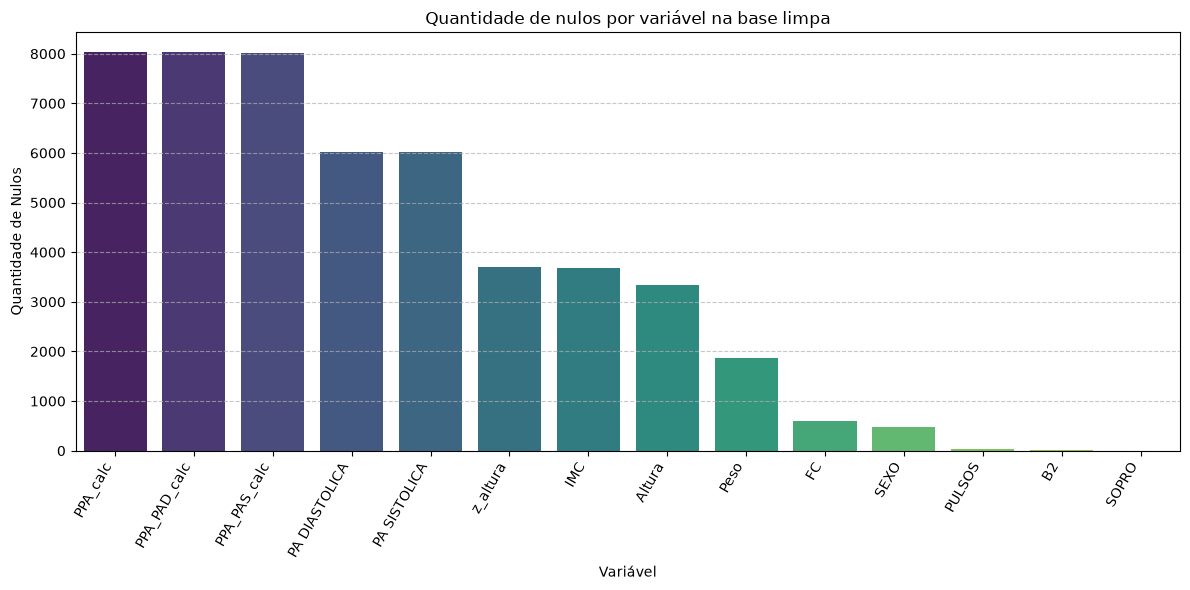

In [25]:
# Mesmo gráfico da versão anterior, agora sobre a base limpa e só com as variáveis que
# ainda têm nulos: mostra o que ficará para a imputação pós-divisão treino/teste.
null_counts = df_limpo.isnull().sum()
null_counts = null_counts[null_counts > 0]

null_counts_df = null_counts.reset_index()
null_counts_df.columns = ['Variavel', 'Quantidade de Nulos']
null_counts_df = null_counts_df.sort_values(by='Quantidade de Nulos', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Variavel', y='Quantidade de Nulos', data=null_counts_df, palette='viridis', hue='Variavel', legend=False)
plt.title('Quantidade de nulos por variável na base limpa')
plt.xlabel('Variável')
plt.ylabel('Quantidade de Nulos')
plt.xticks(rotation=60, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [26]:
# CSV final da limpeza: entrada das próximas etapas (divisão treino/teste e imputação).
df_limpo.to_csv(RAIZ / 'Limpeza' / 'UCMF_limpo.csv', index=False)
print(f'UCMF_limpo.csv salvo: {df_limpo.shape[0]} linhas x {df_limpo.shape[1]} colunas')

UCMF_limpo.csv salvo: 10576 linhas x 51 colunas


In [27]:
# Tabela antes x depois por variável (% de nulos no bruto e no limpo + ação aplicada): é o
# resumo de problemas x soluções usado no relatório.
antes_depois.to_csv(RAIZ / 'Limpeza' / 'antes_depois.csv', index=False, encoding='utf-8-sig')
print('Limpeza/antes_depois.csv salva')

Limpeza/antes_depois.csv salva
